# 3. ¿Cuánto dicen las primeras 10 jornadas del final de la liga?

**Pregunta:** tras 10 de 38 jornadas, ¿podemos fiarnos de la clasificación? ¿Quién está arriba en octubre, sigue arriba en mayo?

Usamos las temporadas completas desde 2012-13. Excluimos la temporada en curso y la 2024-25, a la que le falta la última jornada en la fuente.

In [1]:
import duckdb, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MARTS, IMG = ROOT / "data" / "marts", ROOT / "docs" / "img"
IMG.mkdir(parents=True, exist_ok=True)
con = duckdb.connect()
for t in ["fct_matches", "fct_standings_by_matchday", "fct_final_standings", "mart_home_advantage", "mart_comebacks"]:
    con.execute(f"create view {t} as select * from '{MARTS / (t + '.parquet')}'")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 11})
q = lambda sql: con.execute(sql).df()

In [2]:
pairs = q("""
    with final as (
        select season, team, position as final_pos from fct_final_standings
        where last_matchday = 38 and season not in ('2024-25')
    )
    select s.season, s.matchday, s.team, s.position, f.final_pos
    from fct_standings_by_matchday s join final f using (season, team)""")
print(pairs.season.nunique(), "temporadas completas")

13 temporadas completas


## Correlación entre la posición en cada jornada y la posición final

In [3]:
corr = (pairs.groupby("matchday")
        .apply(lambda g: g["position"].rank().corr(g["final_pos"].rank()), include_groups=False)
        .rename("spearman").reset_index())
print(corr[corr.matchday.isin([1, 5, 10, 15, 19, 25, 30])].to_string(index=False))

 matchday  spearman
        1  0.409717
        5  0.677484
       10  0.780165
       15  0.843130
       19  0.877708
       25  0.916831
       30  0.949648


## Tras la jornada 10: ¿se mantienen arriba y abajo?

In [4]:
md10 = pairs[pairs.matchday == 10]
rows = []
for name, cond_now, cond_final in [
    ("Top 4 en la J10 → acaba top 4 (Champions)", md10.position <= 4, md10.final_pos <= 4),
    ("Top 1 en la J10 → acaba campeón", md10.position == 1, md10.final_pos == 1),
    ("Descenso en la J10 → acaba descendiendo", md10.position >= 18, md10.final_pos >= 18),
]:
    sel = md10[cond_now]
    rows.append({"situación": name, "casos": len(sel), "se_cumple": cond_final[cond_now].mean()})
pd.DataFrame(rows).style.format({"se_cumple": "{:.0%}"})

,situación,casos,se_cumple
0,Top 4 en la J10 → acaba top 4 (Champions),52,79%
1,Top 1 en la J10 → acaba campeón,13,46%
2,Descenso en la J10 → acaba descendiendo,39,54%


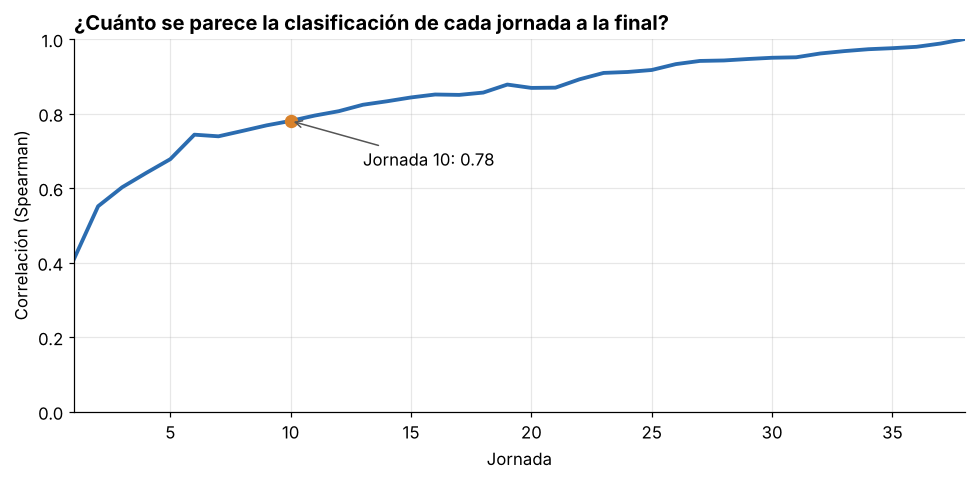

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(corr.matchday, corr.spearman, color="#2b6cb0", lw=2.5)
ax.scatter([10], corr.loc[corr.matchday == 10, "spearman"], color="#d9822b", zorder=3, s=60)
v10 = corr.loc[corr.matchday == 10, "spearman"].iloc[0]
ax.annotate(f"Jornada 10: {v10:.2f}", (10, v10), xytext=(13, v10 - .12),
            arrowprops=dict(arrowstyle="->", color="#555"))
ax.set_ylim(0, 1); ax.set_xlim(1, 38)
ax.set_xlabel("Jornada"); ax.set_ylabel("Correlación (Spearman)")
ax.set_title("¿Cuánto se parece la clasificación de cada jornada a la final?", loc="left", fontweight="bold")
plt.tight_layout(); fig.savefig(IMG / "primeras_jornadas.png", dpi=150); plt.show()

## Conclusiones

- Tras la jornada 10 la clasificación ya se parece bastante a la final: correlación de **0,78** (en la jornada 1 es 0,41 y en la 19, 0,88).
- El **79 %** de los equipos que están en puestos de Champions en la jornada 10 acaban ahí.
- Pero el líder de la jornada 10 solo acaba campeón en **6 de 13** temporadas, y solo el **54 %** de los equipos en descenso en la jornada 10 acaba bajando. Hay mucho margen para reaccionar.

*Nota:* la posición se calcula con desempate por diferencia de goles, no por enfrentamiento directo como hace LaLiga. Afecta poco a estas conclusiones.